# The Traditional Random Walk: A Python Guide

This guide translates the concept of a traditional random walk into Python. A random walk models an object (a `Walker`) that takes successive steps across a window based on randomized choices.

In this traditional model, the walker has four possible steps: right, left, forward (down), and backward (up). The probability of the `Walker` taking a step in a given direction is exactly equal to the probability of taking a step in any other direction. Because there are four options, there is a 1 in 4 (or 25%) chance of moving in any specific direction, resulting in a uniform distribution of steps.

Additionally, because the background is only drawn once during the setup phase rather than being continuously cleared, the `Walker` leaves a cumulative, visible trail of its path over time.

The step-by-step code blocks provided previously break down the Object-Oriented structure required to recreate this simulation, covering the initialization of the `Walker` class, its display method, and the core randomized step logic.

## Traditional Random Walk (Example 1)

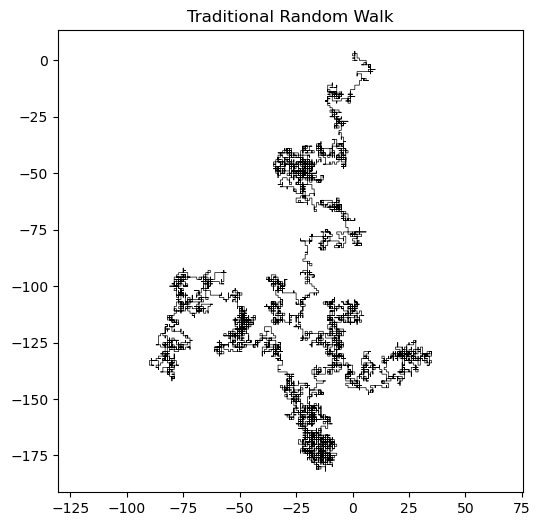

In [4]:
import matplotlib.pyplot as plt
import random

class Walker:
    def __init__(self):
        # Initialize the Walker's starting location[cite: 3]
        self.x = 0
        self.y = 0
        self.history_x = [self.x]
        self.history_y = [self.y]

    def step(self):
        # Pick a random number between 0 and 3[cite: 3]
        choice = random.randint(0, 3) 
        
        if choice == 0:
            self.x += 1
        elif choice == 1:
            self.x -= 1
        elif choice == 2:
            self.y += 1
        else:
            self.y -= 1
            
        self.history_x.append(self.x)
        self.history_y.append(self.y)

w = Walker()
for _ in range(10000): # Simulating the continuous draw() loop[cite: 4]
    w.step()

plt.figure(figsize=(6, 6))
plt.plot(w.history_x, w.history_y, color='black', linewidth=0.5)
plt.title("Traditional Random Walk")
plt.axis('equal')
plt.show()

## Random Number Distribution (Example 1.2)

This tests the uniform distribution of the random number generator by counting how often random numbers are picked.   

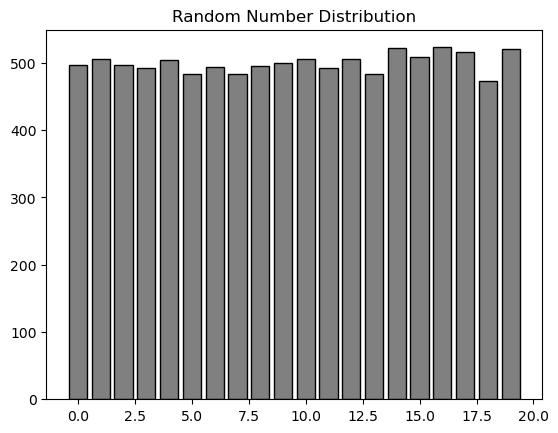

In [5]:
import matplotlib.pyplot as plt
import random

# An array to keep track of how often random numbers are picked[cite: 6]
random_counts = [0] * 20 

# Simulating the draw() loop over many iterations
for _ in range(10000):
    index = random.randint(0, len(random_counts) - 1)
    random_counts[index] += 1

plt.bar(range(len(random_counts)), random_counts, color='gray', edgecolor='black')
plt.title("Random Number Distribution")
plt.show()

## Walker Tending to the Right (Example 1.3)
Using probabilities to generate a non-uniform distribution. This walker has a 40% chance of moving to the right.

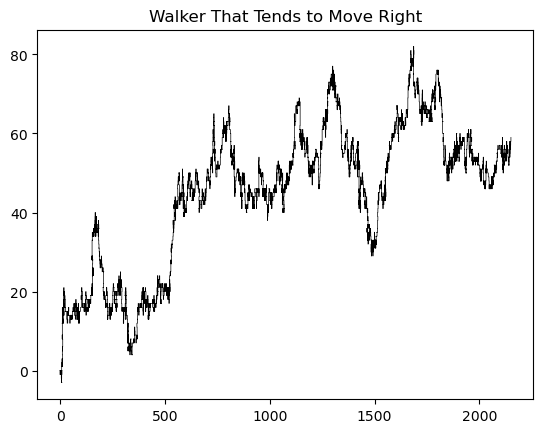

In [6]:
import matplotlib.pyplot as plt
import random

class RightWalker:
    def __init__(self):
        self.x, self.y = 0, 0
        self.history_x, self.history_y = [0], [0]

    def step(self):
        r = random.random() # A random floating point value between 0 and 1[cite: 9]
        
        if r < 0.4:        # 40% chance of moving to the right[cite: 10]
            self.x += 1
        elif r < 0.6:      
            self.x -= 1
        elif r < 0.8:      
            self.y += 1
        else:              
            self.y -= 1
            
        self.history_x.append(self.x)
        self.history_y.append(self.y)

w = RightWalker()
for _ in range(10000):
    w.step()

plt.plot(w.history_x, w.history_y, color='black', linewidth=0.5)
plt.title("Walker That Tends to Move Right")
plt.show()

## 4. Custom Distribution (Monte Carlo Method)
This translates the custom probability distribution algorithm where a higher number has a greater likelihood of being picked.

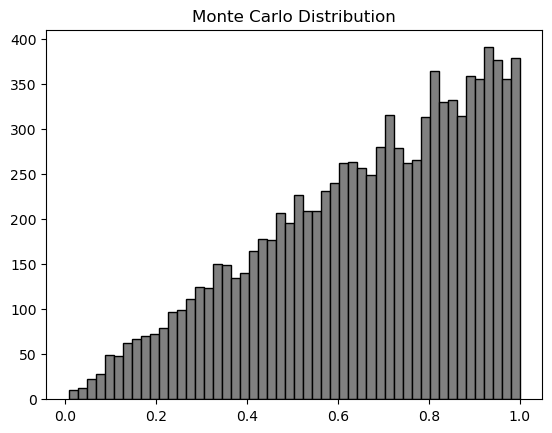

In [7]:
import random
import matplotlib.pyplot as plt

def montecarlo():
    while True: # Do this until we find a qualifying random value[cite: 16]
        r1 = random.random()     # Pick a random value[cite: 16]
        probability = r1         # Assign a probability[cite: 16]
        r2 = random.random()     # Pick a second random value[cite: 16]
        
        if r2 < probability:     # Does it qualify?[cite: 16]
            return r1

# Testing the distribution
results = [montecarlo() for _ in range(10000)]
plt.hist(results, bins=50, color='gray', edgecolor='black')
plt.title("Monte Carlo Distribution")
plt.show()

## 5: Perlin Noise Walker (Example 1.5)
Perlin noise produces a naturally ordered, smooth sequence of pseudo-random numbers. To use this in Python, you can install the noise library (pip install noise).

In [8]:
import matplotlib.pyplot as plt
from noise import pnoise1

class NoiseWalker:
    def __init__(self):
        self.tx = 0.0
        self.ty = 10000.0 # Start y at 10,000 so x and y act independently[cite: 22]
        self.history_x = []
        self.history_y = []

    def step(self):
        # Generate noise and map it (pnoise1 returns -1 to 1; map it to 0-640 for width)
        # Using a width of 640 and height of 360[cite: 21]
        x = (pnoise1(self.tx) + 1) / 2 * 640 
        y = (pnoise1(self.ty) + 1) / 2 * 360 
        
        self.history_x.append(x)
        self.history_y.append(y)
        
        self.tx += 0.01 # Move forward through "time"[cite: 21]
        self.ty += 0.01

w = NoiseWalker()
for _ in range(1000):
    w.step()

plt.plot(w.history_x, w.history_y, color='black', alpha=0.5)
plt.scatter(w.history_x[-1], w.history_y[-1], color='black', s=100) # Draw current position
plt.title("Perlin Noise Walker")
plt.xlim(0, 640)
plt.ylim(0, 360)
plt.gca().invert_yaxis()
plt.show()

ModuleNotFoundError: No module named 'noise'